# Survivor functions from a Cox model with two factors, and the risk-adjusted survivor function

Once a Cox model is fitted, the survivor function of an individual with explanatory variables $x_i$ is estimated by

$$
\hat S_i(t)=\hat S_0(t)^{\exp(\hat\beta^Tx_i)},
$$

where $\hat S_0(t)$ is the estimated baseline survivor function. We use it to compare the levels of each factor, and to summarize the whole sample with the risk-adjusted survivor function, which is the average of the estimated survivor functions of all the individuals:

$$
\bar S(t)=\frac{1}{n}\sum_{i=1}^n\hat S_i(t).
$$

The data are the survival times, in months, of 36 patients with hypernephroma, with the factors `nephrectomy` (0 = no, 1 = yes) and `age` (1 = under 60, 2 = 60 to 70, 3 = over 70).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter, CoxPHFitter

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
opt_color   = '#E69F00'
ref_color   = '#333333'
CLASS_COLORS = ['#1f4e79', '#E69F00', '#009E73']

## The data

In [3]:
DatOriginal = pd.read_csv("data/hypernephroma_treatment.dat", sep=r"\s+")

In [4]:
DatOriginal.head()

,nephrectomy,age,time,status
0,0,1,9,1
1,0,1,6,1
2,0,1,21,1
3,0,2,15,1
4,0,2,8,1


## The model

In [5]:
cph = CoxPHFitter()
Model = cph.fit(DatOriginal, 'time', 'status', formula='C(age)+C(nephrectomy)')

In [6]:
Model.print_summary()

<lifelines.CoxPHFitter: fitted with 36 total observations, 4 right-censored observations>
             duration col = 'time'
                event col = 'status'
      baseline estimation = breslow
   number of observations = 36
number of events observed = 32
   partial log-likelihood = -82.11
         time fit was run = 2026-10-13 02:25:33 UTC

---
                     coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                            
C(age)[T.2]          0.02      1.02      0.43           -0.81            0.85                0.44                2.35
C(age)[T.3]          1.36      3.90      0.60            0.19            2.53                1.21               12.56
C(nephrectomy)[T.1] -1.40      0.25      0.52           -2.41           -0.39                0.09                0.68

                     cmp to     z    p  -log2(p)
covariate                                       
C(age)[T.2]            0.00  0.05 0.96      0.06
C(age)[T.3]            0.00  2.28 0.02      5.46
C(nephrectomy)[T.1]    0.00 -2.72 0.01      7.26
---
Concordance = 0.67
Partial AIC = 170.22
log-likelihood ratio test = 12.36 on 3 df
-log2(p) of ll-ratio test = 7.32

Hazard ratios against the reference levels (under 60, no nephrectomy), with their 95% confidence intervals.

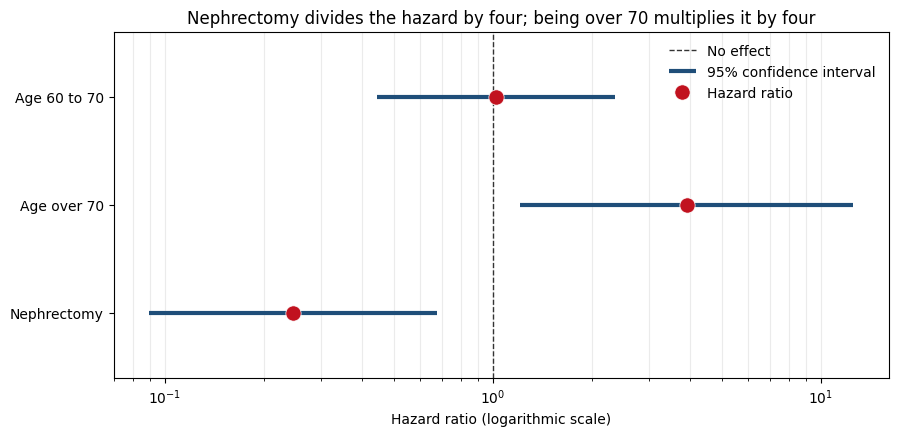

In [7]:
Summary = Model.summary
position = np.arange(len(Summary))[::-1]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvline(1, color=ref_color, lw=1, ls='--', label='No effect')
ax.hlines(position, Summary['exp(coef) lower 95%'], Summary['exp(coef) upper 95%'], color=line_color, lw=3,
          label='95% confidence interval')
ax.plot(Summary['exp(coef)'], position, 'o', color=point_color, markersize=11, markeredgecolor='white',
        markeredgewidth=0.5, label='Hazard ratio')
ax.set_yticks(position, ['Age 60 to 70', 'Age over 70', 'Nephrectomy'])
ax.set_ylim(-0.6, len(Summary)-0.4)
ax.set_xscale('log')
ax.set_xlabel('Hazard ratio (logarithmic scale)')
ax.set_title('Nephrectomy divides the hazard by four; being over 70 multiplies it by four')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, axis='x', which='both', alpha=0.25)

## Survivor functions for the levels of each factor

In [8]:
def PlotSurvivorFunctions(ax, survivor, labels, colors):
    # Estimated survivor functions (one column per individual), as step functions starting at 1
    for column, label, color in zip(survivor.columns, labels, colors):
        ax.step(np.append(0, survivor.index), np.append(1, survivor[column]), where='post', color=color, lw=2, label=label)
    ax.set_xlabel('Time (months)')
    ax.set_xlim(0, None)
    ax.set_ylim(0, 1.02)
    ax.legend(loc='upper right', frameon=False)
    ax.grid(True, alpha=0.25)

In [9]:
#ax = Model.baseline_survival_.plot(drawstyle="steps-post")
SurvivorNephrectomy = Model.predict_survival_function(
    pd.DataFrame({'nephrectomy':[0,1], 'age':[1,1]}, index=['neph0_age1', 'neph1_age1'])
)

In [10]:
#ax = Model.baseline_survival_.plot(drawstyle="steps-post")
SurvivorAge = Model.predict_survival_function(
    pd.DataFrame({'nephrectomy':[0,0,0], 'age':[1,2,3]}, index=['neph0_age1', 'neph0_age2', 'neph0_age3'])
)

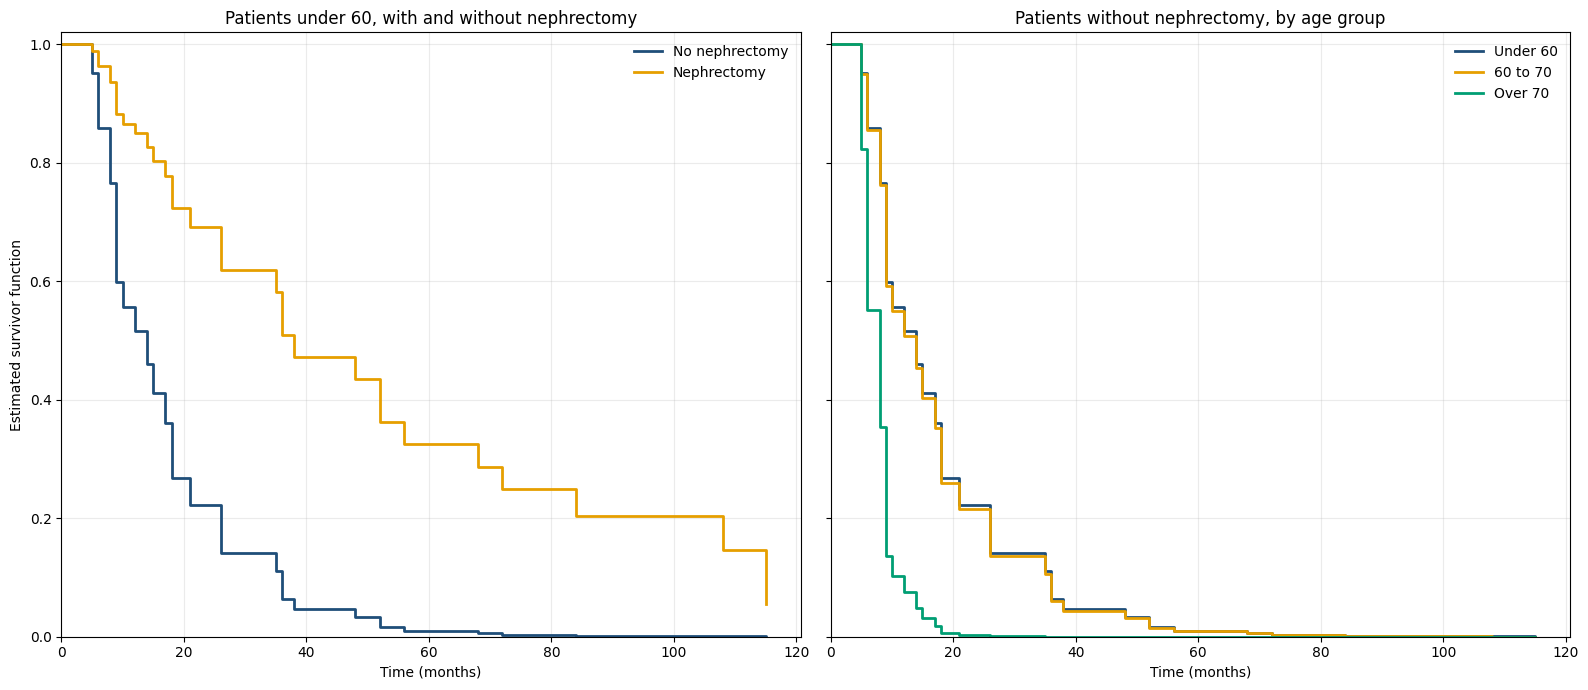

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
PlotSurvivorFunctions(axes[0], SurvivorNephrectomy, ['No nephrectomy', 'Nephrectomy'], CLASS_COLORS)
PlotSurvivorFunctions(axes[1], SurvivorAge, ['Under 60', '60 to 70', 'Over 70'], CLASS_COLORS)
axes[0].set_ylabel('Estimated survivor function')
axes[0].set_title('Patients under 60, with and without nephrectomy')
axes[1].set_title('Patients without nephrectomy, by age group')
plt.tight_layout()

## Risk-adjusted survivor function

The average of the survivor functions of the 36 patients, compared with the Kaplan-Meier estimator, which does not use the explanatory variables.

In [12]:
kmf = KaplanMeierFitter()
kmf.fit(DatOriginal['time'], event_observed=DatOriginal['status'])

RiskAdjusted = Model.predict_survival_function(DatOriginal).mean(axis=1)

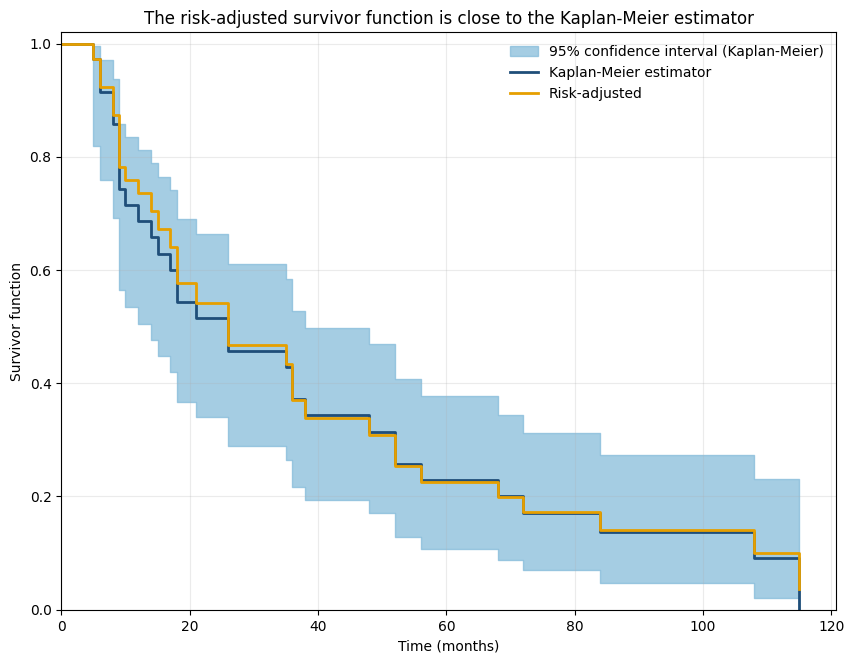

In [13]:
fig, ax = plt.subplots(figsize=(10, 7.5))
ci = kmf.confidence_interval_
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=ci_color, alpha=0.7,
                label='95% confidence interval (Kaplan-Meier)')
ax.step(kmf.survival_function_.index, kmf.survival_function_.iloc[:, 0], where='post', color=line_color, lw=2,
        label='Kaplan-Meier estimator')
ax.step(np.append(0, RiskAdjusted.index), np.append(1, RiskAdjusted), where='post', color=opt_color, lw=2,
        label='Risk-adjusted')

ax.set_xlabel('Time (months)')
ax.set_ylabel('Survivor function')
ax.set_xlim(0, None)
ax.set_ylim(0, 1.02)
ax.set_title('The risk-adjusted survivor function is close to the Kaplan-Meier estimator')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)